# Uncertainty Estimation with Probabilistic Discriminative Deep Networks

In this implementation exercise, we explore the notions of aleatoric and epistemic uncertainties and practice modelling such uncertainties for simple deep networks.

## Introduction
In standard discriminative modelling, we try to learn the parameters $\mathbf{\theta}$ of a deep network $f_{\mathbf{\theta}}:\mathcal{X}\rightarrow \mathcal{Y}$ that maps an input $x\in\mathcal{X}=\mathbb{R}^d$ to its corresponding output $\hat{y}=f_{\mathbf{\theta}}(\mathbf{x})\in\mathcal{Y}$. The parameters $\theta \in \mathbb{R}^p$ are trained on a training set of $n$ samples $\mathcal{D}=\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$

Predictive uncertainty estimation is concerned with reflecting a *degree of confidence* with a deep network's prediction. That is, instead of directly mapping the input $\mathbf{x}$ to the corresponding prediction $\hat{y}$, it maps it to a distribution over possible outputs $\hat{P}(y|\mathbf{x})$.

In this implementation practical, we first create a toy dataset and then try simple techniques to model two main types of uncertainties: *aleatoric* and *epistemic*.

## Types of Uncertainty
**Aleatoric uncertainty**, also known as irreducible uncertainty, refers to the inherent uncertainty that is present in the observations $(\mathbf{x},y)$. For instance, the measurements (*e.g.,* length of a tool) can be noisy depending on the precision of the measuring device (*e.g.*, a ruler with one-centimeter markings). It is irreducible **conditional on the available inputs and the observation process**: collecting more examples does not remove the noise in a new observation. Better measurements or additional informative inputs can reduce it. Aleatoric uncertainty can be either *homoscedastic* or *heteroscedastic*. Homoscedastic aleatoric uncertainty does not depend on a sample $\mathbf{x}$ (*e.g.*, the length of a tool can always have a fixed error of up to one centimeter) while a heteroscedastic aleatoric uncertainty can change depending on the sample (*e.g.*, a depth camera might give more error on certain surfaces than others depending on the material of the surface and reflectance and illuminance properties).  

**Epistemic uncertainty**, also known as knowledge uncertainty,  is induced by a model's lack of (enough) knowledge about a certain sample to make a confident prediction on it. Epistemic predictive uncertainty generally depends on the input, but it need not vary with it. Here we represent parameter uncertainty using a distribution over network weights. This does not automatically capture model misspecification or guarantee reliable uncertainty on out-of-distribution inputs. More informative data can reduce parameter uncertainty; its quality also depends on the model, prior, and inference approximation.

We will use a few simple methods, described in the lectures, to tackle these uncertainties by using

i) Maximum Likelihood Estimation (MLE) of aleatoric uncertainty, and

ii) Variational Inference (VI) and a KL-weighted variant for approximate parameter-induced epistemic uncertainty.

But let's first create a simple toy dataset.


## Running and completing the practical
Use Google Colab or a Python 3 Jupyter kernel. Upload this `.ipynb` file directly to Colab; no math-rendering installation is needed. If dependencies are missing, run `%pip install "jax[cpu]" numpy matplotlib tqdm` in a separate cell, then restart the kernel. A CPU is sufficient; no data downloads are required. Run the notebook from top to bottom.

Complete **two derivations** (Gaussian maximum likelihood and the VI objective) and **three functions** (`loss_mle_homoscedastic`, `vi_fc_layer_forward`, and `vi_loss`). Also answer the interpretation questions near the plots. The student notebook deliberately raises `NotImplementedError` at an unfinished implementation; replace each placeholder before continuing. The separate instructor notebook contains worked derivations, implementations, and executed outputs.

Data arrays have shape `(number_of_points, number_of_features_or_outputs)`. Network functions use columns as examples, so their inputs and targets have shapes `(input_dim, batch_size)` and `(output_dim, batch_size)`. Training loops perform the transpose. Keep predictions and targets the same shape to avoid accidental broadcasting.

The seed is fixed for reproducibility. Separate fits deliberately start from the same initialization for a controlled comparison. GPU results and results with other library versions can differ. The clean test curve includes both interpolation and extrapolation; it is a diagnostic, not a validation set for tuning hyperparameters.

**Note.** for this year an LLM has been used to polish this course exercise. Please report to the teachers if you encounter an issue with the notebook.


In [90]:
#@title Import the necessary libraries for creating the data (numpy) and plotting it
import numpy as np
import matplotlib.pyplot as plt
import tqdm

# Re-run this cell to reset the NumPy noise stream.

%matplotlib inline

rand_seed = 123

np.random.seed(rand_seed)

# Toy Regression Dataset Creation

## Introduction
In this exercise the goal is to familiarize the students with basic concepts of deep probabilistic modelling. As such, we create and use a toy dataset since it will 1) allow us to put more emphasis on the pedagogical aspect of the practical, 2) it will make visualizing the important concepts easier, and 3) reduce the computational load necessary for the analysis.

## Underlying Function
For this toy dataset, we consider a one-dimensional regression task $\mathcal{X}=\mathbb{R}\rightarrow\mathcal{Y}=\mathbb{R}$. The underlying true function is the periodic even cosine function $y=\text{cos}(x)$. Modelling a periodic function can be generally challenging for a deep network.

## Basic Clean Training Set
For the basic clean training set $\mathcal{D}$, we create $n=100$ samples with $x\in[-1.3\pi,1.3\pi]$ and store them in the following variables.

```
# X_train       # training points input
# Y_train_true  # training points clean label
```



In [91]:
#@title define a function to sample from the true distribution
def sample_cosine(n_samples,
                  domain,
                  gaussian_noise_std=None,
                  heteroscedastic_noise_fun=None):
    assert gaussian_noise_std is None or heteroscedastic_noise_fun is None,\
        "Provide at most one of gaussian_noise_std and heteroscedastic_noise_fun."
    # Use a deterministic, evenly spaced grid (not independent uniform draws).
    x = np.linspace(domain[0],
                    domain[1],
                    n_samples).reshape(-1, 1)

    if gaussian_noise_std is None and heteroscedastic_noise_fun is None:
        y = np.cos(x)
    else:
        gaussian_noise = np.random.randn(n_samples, 1)
        if heteroscedastic_noise_fun is None:
            y = np.cos(x) + gaussian_noise * gaussian_noise_std
        else:
            y = np.cos(x)
            y = y + heteroscedastic_noise_fun(gaussian_noise,x,y)

    return x,y

In [92]:
n_train = 100
domain_train= np.pi * np.array([-1.3, 1.3])
X_train, Y_train_true = sample_cosine(n_train,
                                      domain_train)

let's visually inspect our clean training data

In [93]:
#@title Define a function for visualization
def visualize_samples(samples_list,ux,uy,domain_visualization,title, figsize=(15, 4)):
    fig = plt.figure(figsize=figsize)
    for x_samples,y_samples,kwargs in samples_list:
        plt.scatter(x_samples, y_samples,**kwargs)

    plt.plot(ux, uy, linewidth=3, label='Underlying Function')
    plt.xlim(domain_visualization)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1,1), loc="upper left")
    plt.grid()

In [94]:
#@title Sample at a higher resolution for visualization of the true function
domain_visualization = np.pi * np.array([-3.2, 3.2])
visualization_resolution = 1000
ux, uy = sample_cosine(visualization_resolution,
                       domain_visualization)

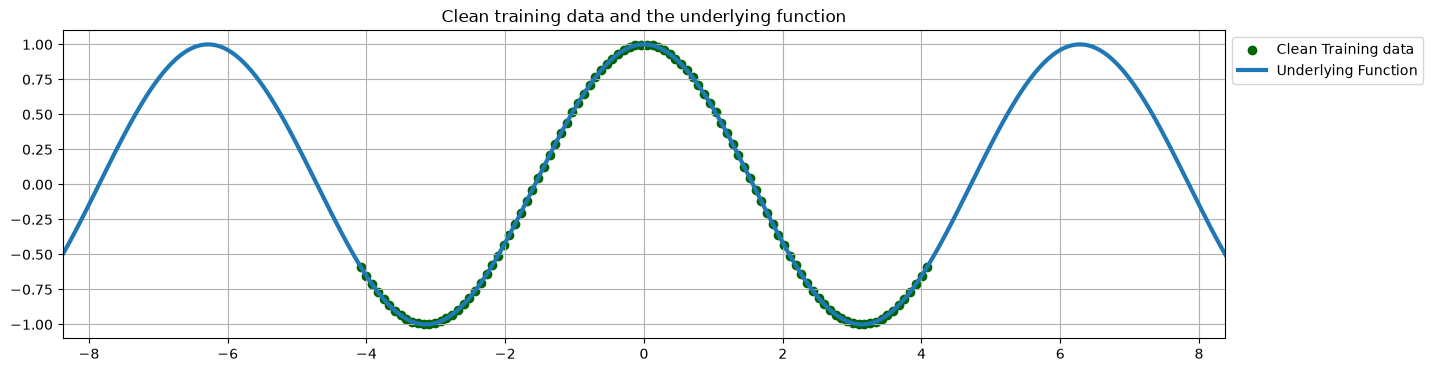

In [95]:
#@title Visualize training data
visualization_train_kwargs = {'marker':'o',
                              'linewidth':1,
                              'color':'darkgreen',
                              'label':'Clean Training data'}
visualize_samples_list = [(X_train,
                           Y_train_true,
                           visualization_train_kwargs)]
zooming_factor=1.2
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization/zooming_factor,
                  title='Clean training data and the underlying function')

The training inputs form an evenly spaced grid over $[-1.3\pi, 1.3\pi]$.

## Basic Clean Test Set
Now let's create a test set that covers inputs beyond the observed interval during training. For the basic clean test set $\mathcal{D}_{test}$, we create $n_{test}=200$ samples with $x\in[-3\pi,3\pi]$ and store them in the following variables.

```
# X_test       # test points input
# Y_test_true  # test points clean label
```

In [96]:
n_test = 200
domain_test = np.pi * np.array([-3, 3])
X_test, Y_test_true = sample_cosine(n_test,
                                    domain_test)

let's visually inspect our clean test and training data

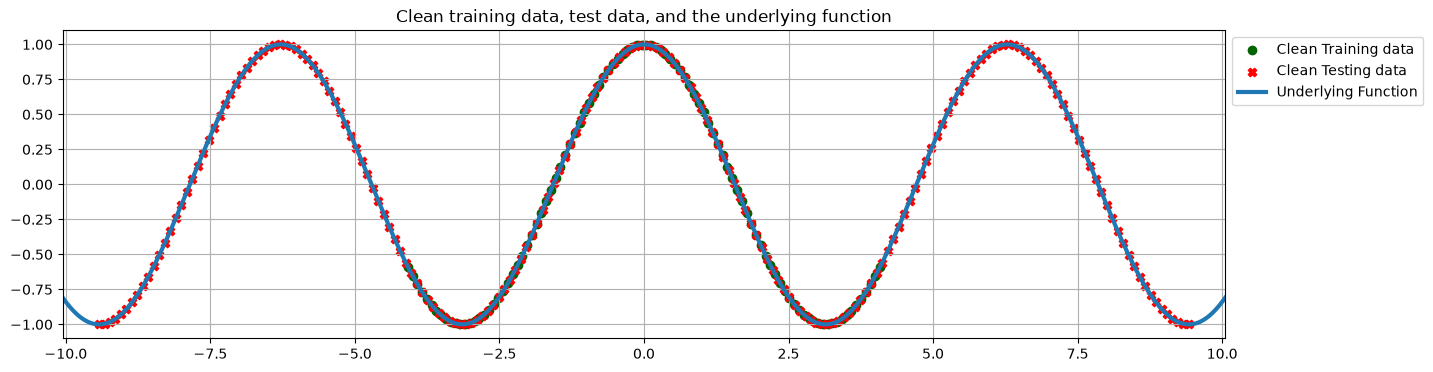

In [97]:
visualization_test_kwargs={'marker':'X',
                           'linewidth':1,
                           'color':'red',
                           'label':'Clean Testing data'}
# update visualization list
visualize_samples_list.append(
    (X_test,
     Y_test_true,
     visualization_test_kwargs))
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Clean training data, test data, and the underlying function')

## Homoscedastic Gaussian Noise on the Training Set
Datasets are commonly noisy and this noise can be due to various reasons, for instance because of the measurement errors. So, a more realistic dataset will contain some noise in the labels. We will first create a dataset containing *homoscedastic* label noise -- a noise independent of the sample. For this, we choose an additive Gaussian noise $\mathcal{N}(0,\sigma^2)$ with variance $\sigma^2=0.01$. We call the dataset with the homoscedastic noise $\mathcal{D}^{homo}$. It contains the same input samples as that of $\mathcal{D}$ but the corresponding labels $y$ are generated with additive gaussian noise and stored in the following variable.

```
# Y_train_hom  # labels with homoscedastic additive Gaussian noise
```

In [98]:
noise_std = 0.1
# sample again with noise
X_train, Y_train_hom = sample_cosine(n_train,
                                     domain_train,
                                     gaussian_noise_std=noise_std)

Now, let us visualize the training data with homoscedastic label noise this time.

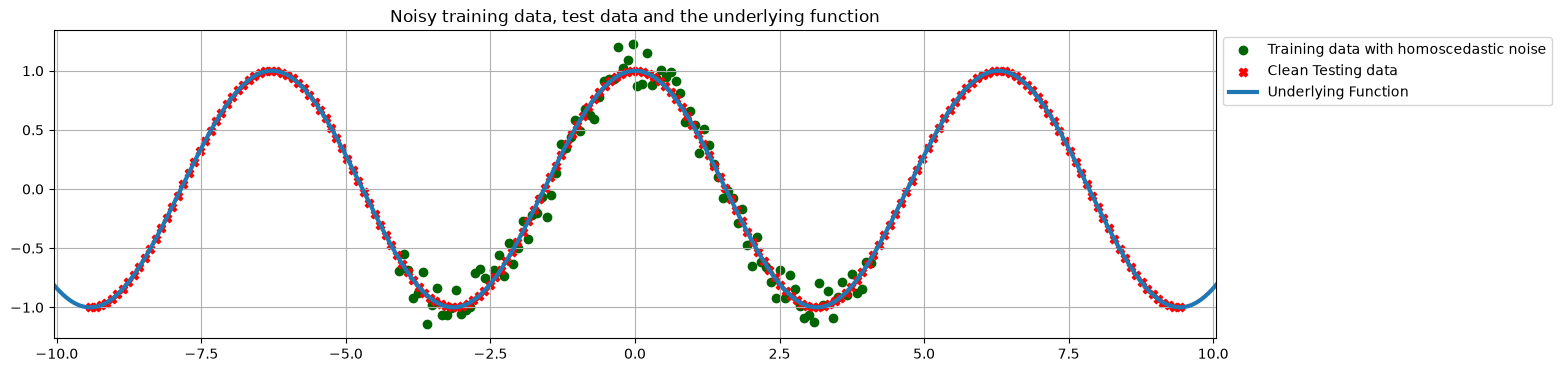

In [99]:
# update visualization information
visualization_train_kwargs['label']='Training data with homoscedastic noise'
visualize_samples_list[0]=(X_train,
                           Y_train_hom,
                           visualization_train_kwargs)
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Noisy training data, test data and the underlying function')

## Heteroscedastic Noise on the Training Set
We then create another dataset, but this time, containing *heteroscedastic* label noise -- a noise that is dependent on the sample. It is common for the label noise to be dependent on (specifically proportional to) the magnitude for continuous labels. For this reason, we choose a *multiplicative* Gaussian noise $\mathcal{N}(\mu,\sigma^2)$ with mean $\mu=1$ and variance $\sigma^2=0.04$. We call the dataset with the heteroscedastic noise $\mathcal{D}^{het}$. It contains the same input samples as that of $\mathcal{D}$ but the corresponding labels $y$ are generated with multiplicative gaussian noise and stored in the following variable.

```
# Y_train_het  # labels with heteroscedastic multiplicative Gaussian noise
```

Equivalently, $y=\cos(x)(1+0.2\epsilon)$ with $\epsilon\sim\mathcal N(0,1)$. Thus $\mathbb E[y\mid x]=\cos(x)$ and $\operatorname{Var}(y\mid x)=0.04\cos^2(x)$: the conditional standard deviation is $0.2|\cos(x)|$. At zeros of the cosine, the observation is deterministic in this toy model.


In [100]:
noise_std = 0.2
noise_mean = 1
noise_fun = lambda noise,x,y: (noise_std * noise + noise_mean - 1) * y
X_train, Y_train_het = sample_cosine(n_train,
                                     domain_train,
                                     heteroscedastic_noise_fun=noise_fun)

Now, let us visualize the training data with heteroscedastic label noise this time.

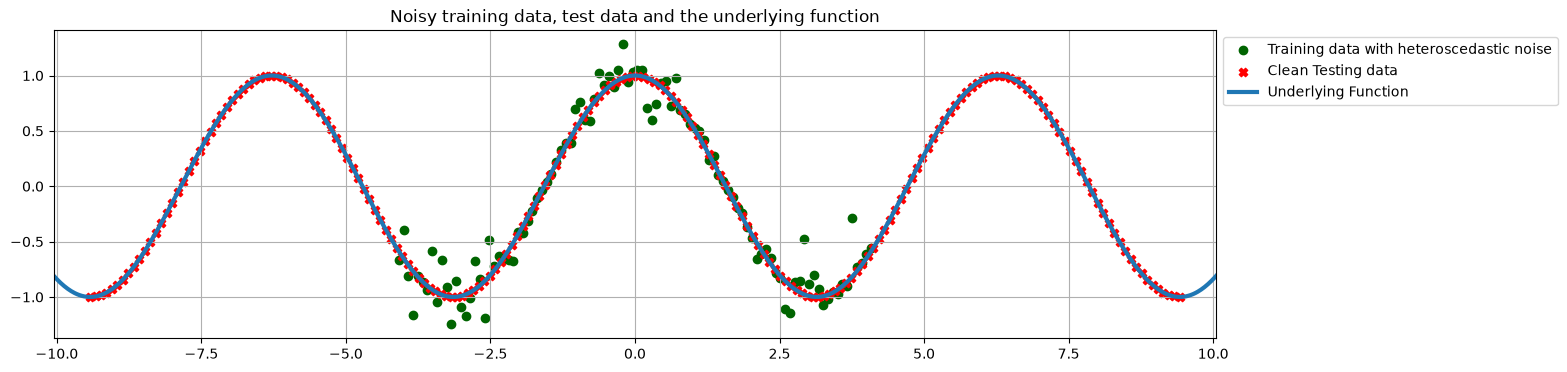

In [101]:
# update visualization information
visualization_train_kwargs['label']='Training data with heteroscedastic noise'
visualize_samples_list[0]=(X_train,
                           Y_train_het,
                           visualization_train_kwargs)
visualize_samples(visualize_samples_list,
                  ux,
                  uy,
                  domain_visualization,
                  title='Noisy training data, test data and the underlying function')

The conditional noise standard deviation is largest when the cosine is close to $1$ or $-1$ and smallest near its zeros. Judge this from vertical residuals, not from the apparent width of the point cloud along the curve.

# Risk Minimization

In a regularized risk minimization scheme, we train a model parametrized by $\mathbf{\theta}$, on a training set $\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n}$, using the following minimization:

$$
\begin{aligned}
\mathbf{\theta}^*
&=\operatorname*{arg\,min}_{\mathbf{\theta}}
\left[\mathcal L(\mathcal D)+\Omega(\mathbf{\theta})\right]\\
&=\operatorname*{arg\,min}_{\mathbf{\theta}}
\left[\sum_{i=1}^{n}l(f_\theta(x_i),y_i)+\Omega(\mathbf{\theta})\right].
\end{aligned}
\tag{1}
$$

where $\mathcal{L}$ is the total loss function operating on the whole training set, $l$ is the sample loss function operating on individual training pairs $(x_i,y_i)$ and $\Omega$ is a regularization cost function.

It is common to use the average loss $\frac{1}{n}\sum_{i=1}^{n}l(f_\theta(x_i),y_i)$ instead of a sum. If a regularizer is included, its coefficient must also be scaled consistently to preserve the same objective.

## Training a Multi-Layer Perceptron (MLP)
Initially, we train a MLP, also known as fully-connected network, parametrized by its weights and biases $\mathbf{\theta}$. We use three hidden layers of size 100,40,100 units and the Rectified Linear Unit (ReLU), $\max(0,h)$, as the activation function. We use mean squared error (MSE). The baseline below does **not** implement weight decay: it is the unregularized case $\Omega(\theta)=0$ of the general expression above. Throughout this practical, we use Jax as the framework to implement our deep networks.

### Jax Deep Learning Framework
JAX provides a NumPy-like API, automatic differentiation, and just-in-time compilation for CPU and accelerators. Use `jax.numpy` for differentiable calculations; use NumPy for data creation and plotting. See the [JAX documentation](https://docs.jax.dev/en/latest/).

Let us first import the necessary Jax libraries.

In [102]:
import time

import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, value_and_grad
from jax import random
from jax import nn
from jax.example_libraries import optimizers

from functools import partial

# initialize the random generator
key = random.PRNGKey(rand_seed)

print("JAX version:", jax.__version__, "| Devices:", jax.devices())

JAX version: 0.12.0 | Devices: [CpuDevice(id=0)]


Next, we define the configuration of the fully-connected (FC) network:

In [103]:
# standard network's configurations
input_dim = X_train.shape[1]
output_dim = Y_train_true.shape[1]
layers_width = [100, 40, 100]
num_epochs = 1000
step_size = 1e-2

Now, we define two python functions; one for initializing the parameters of a FC *layer* and another for the feed-forward computation of a FC *layer*.

In [104]:
# Initialize the parameters of a standard fully-connected layer
def standard_fc_layer_init(input_dim, output_dim, key, scale=1e-2):
    keys = random.split(key, 2)
    weights = random.normal(keys[0], (output_dim, input_dim)) * scale
    biases  = random.normal(keys[1], (output_dim, 1)) * scale
    return weights, biases

In [105]:
# Forward pass of a standard fully-connected layer
def standard_fc_layer_forward(input, weights, biases):
    return jnp.dot(weights, input) + biases

Next, we define two python functions; one for initializing the parameters of a FC *network* and another for the feed-forward computation of a FC *network*.

In [106]:
# Initialize A standard fully-connected network
def standard_fc_network_init(input_dim, layers_width, output_dim, key):
    network_feature_dims = [input_dim, *layers_width, output_dim]
    number_of_layers = len(network_feature_dims[:-1])
    keys = random.split(key, number_of_layers)
    params = [standard_fc_layer_init(network_feature_dims[i],
                                    network_feature_dims[i+1],
                                    keys[i])
                for i in range(number_of_layers)]
    return params

In [107]:
# Forward pass of a standard fully-connected network
def standard_fc_network_forward(input, params, is_classification=False):
    representation = input
    for weights,biases in params[:-1]:
        representation = nn.relu(standard_fc_layer_forward(representation, weights, biases))
    representation = standard_fc_layer_forward(representation,params[-1][0], params[-1][1])

    if is_classification:
        # Classes are rows and examples are columns.
        return nn.log_softmax(representation, axis=0)

    return representation

In the following, we define a python function corresponding to the mean squared error (MSE) loss, as

$$
\mathcal{L}(\mathcal{D})=\frac{1}{n}\sum_{i=1}^{n}l(f_\theta(x_i),y_i)=\frac{1}{n}\sum_{i=1}^{n}(f_\theta(x_i)-y_i)^2
$$



In [108]:
@jit
def loss_mse(params, X, Y):
    """Mean squared error; predictions and targets must have the same shape."""
    preds = standard_fc_network_forward(X, params)
    if preds.shape != Y.shape:
        raise ValueError(f"Prediction shape {preds.shape} does not match target shape {Y.shape}.")
    return jnp.mean((preds - Y) ** 2)

Finally, we implement the code necessary for optimizing the network's parameters using the training data.

In [109]:
# The optimizer functions are explicit static arguments: changing the optimizer
# or its learning rate cannot silently reuse a stale global captured by JIT.
@partial(jit, static_argnames=("loss", "opt_update_fn", "get_params_fn"))
def update(step, params, X, Y, opt_state, loss, opt_update_fn, get_params_fn):
    value, grads = value_and_grad(loss)(params, X, Y)
    opt_state = opt_update_fn(step, grads, opt_state)
    return get_params_fn(opt_state), opt_state, value

In [110]:
def run_training_loop(num_epochs, opt_state, X, Y, X_test, Y_test, num_layers, loss):
    """Full-batch training from a fresh optimizer state (one step per epoch).

    Training MSE is measured against the supplied (possibly noisy) labels.
    Test MSE is measured against the clean curve, both inside and outside
    the training-input interval. Do not use this test curve for model selection.
    """
    train_loss, train_mse, test_mse = [], [], []
    params = get_params(opt_state)
    loss_eval = jit(loss)

    def record():
        values = (loss_eval(params, X.T, Y.T),
                  loss_mse(params[:num_layers], X.T, Y.T),
                  loss_mse(params[:num_layers], X_test.T, Y_test.T))
        values = tuple(float(v) for v in values)  # Synchronize device work.
        if not np.all(np.isfinite(values)):
            raise FloatingPointError("Non-finite loss/MSE. Check the loss and learning rate.")
        for history, value in zip((train_loss, train_mse, test_mse), values):
            history.append(value)

    record()
    print(f"Starting loss: {train_loss[-1]:.6f} | Train MSE: {train_mse[-1]:.6f}")
    for epoch in range(num_epochs):
        start_time = time.perf_counter()
        params, opt_state, _ = update(epoch, params, X.T, Y.T, opt_state,
                                      loss, opt_update, get_params)
        record()  # All three metrics refer to the updated parameters.
        if epoch == 0 or (epoch + 1) % 200 == 0:
            print(f"Epoch {epoch + 1} | T: {time.perf_counter() - start_time:.4f}s"
                  f" | Train loss: {train_loss[-1]:.6f}"
                  f" | Train MSE: {train_mse[-1]:.6f}"
                  f" | Clean-test MSE (all): {test_mse[-1]:.6f}")

    pred = np.asarray(standard_fc_network_forward(X_test.T, params[:num_layers])).T
    inside = (X_test[:, 0] >= X[:, 0].min()) & (X_test[:, 0] <= X[:, 0].max())
    for label, mask in (("interpolation", inside), ("extrapolation", ~inside)):
        if np.any(mask):
            mse = np.mean((pred[mask] - Y_test[mask]) ** 2)
            print(f"Final clean-test MSE ({label}): {mse:.6f}")
    return params, train_loss, train_mse, test_mse

In [111]:
def visualize_predictions(Y_test_pred, title_text, X_train=None, Y_train=None,
                          sigma_param=None, uncertainty_label="Aleatoric: mean ± 2 SD",
                          total_sigma_param=None):
    """Plot bands in standard-deviation units, without clipping their extent.

    A mean ± 2 SD band is not automatically a calibrated 95% interval,
    particularly when the predictive distribution is a non-Gaussian mixture.
    """
    mean = np.asarray(Y_test_pred).reshape(-1)
    if mean.size != X_test.shape[0]:
        raise ValueError("One prediction is required per test input.")
    fig, ax = plt.subplots(figsize=(15, 4))
    curve_x = np.linspace(domain_test[0], domain_test[1], 1000)
    ax.plot(curve_x, np.cos(curve_x), linewidth=3, label="Underlying function")
    ax.plot(X_test.ravel(), mean, linewidth=2, label="Predicted mean")
    if total_sigma_param is not None:
        total_std = np.broadcast_to(np.asarray(total_sigma_param).reshape(-1), mean.shape)
        ax.fill_between(X_test.ravel(), mean - 2*total_std, mean + 2*total_std,
                        alpha=0.15, label="Total predictive: mean ± 2 SD")
    if sigma_param is not None:
        std = np.broadcast_to(np.asarray(sigma_param).reshape(-1), mean.shape)
        if np.any(std < 0) or not np.all(np.isfinite(std)):
            raise ValueError("Standard deviations must be finite and nonnegative.")
        ax.fill_between(X_test.ravel(), mean - 2*std, mean + 2*std,
                        alpha=0.3, label=uncertainty_label)
    if X_train is not None and Y_train is not None:
        ax.scatter(np.asarray(X_train).ravel(), np.asarray(Y_train).ravel(),
                   marker="o", s=18, label="Training observations")
    ax.set(xlabel="x", ylabel="y", title=title_text)
    ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
    ax.grid()
    fig.tight_layout()
    return fig, ax

With everything in place, now, let us launch the training for the clean dataset and visualize the learnt function.

In [112]:
# Initialize the network parameters
params = standard_fc_network_init(input_dim,
                                  layers_width,
                                  output_dim,
                                  key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params)

params,\
train_loss,\
train_mse,\
test_mse = run_training_loop(num_epochs,
                             opt_state,
                             X_train,
                             Y_train_true,
                             X_test,
                             Y_test_true,
                             len(layers_width)+1,
                             loss_mse)

Starting loss: 0.554691 | Train MSE: 0.554691
Epoch 1 | T: 0.1914s | Train loss: 0.547126 | Train MSE: 0.547126 | Clean-test MSE (all): 0.502733
Epoch 200 | T: 0.0003s | Train loss: 0.000328 | Train MSE: 0.000328 | Clean-test MSE (all): 0.744843
Epoch 400 | T: 0.0003s | Train loss: 0.000041 | Train MSE: 0.000041 | Clean-test MSE (all): 1.255070
Epoch 600 | T: 0.0003s | Train loss: 0.000058 | Train MSE: 0.000058 | Clean-test MSE (all): 1.537615
Epoch 800 | T: 0.0003s | Train loss: 0.000134 | Train MSE: 0.000134 | Clean-test MSE (all): 1.639209
Epoch 1000 | T: 0.0003s | Train loss: 0.000041 | Train MSE: 0.000041 | Clean-test MSE (all): 1.635654
Final clean-test MSE (interpolation): 0.000032
Final clean-test MSE (extrapolation): 2.869545


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on $\\bf{clean\\, training\\, data}$'}, xlabel='x', ylabel='y'>)

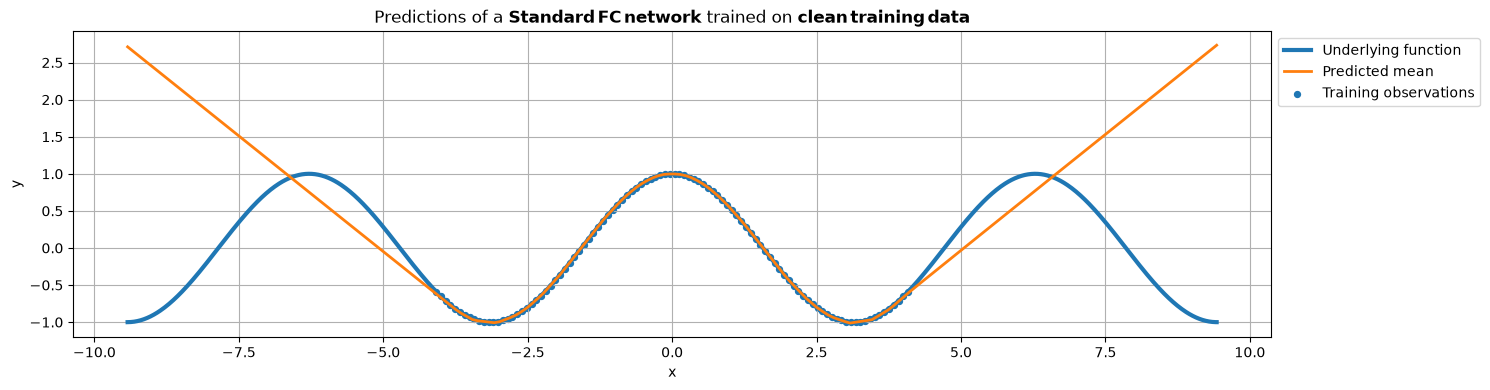

In [113]:
Y_test_pred = standard_fc_network_forward(X_test.T, params)
visualize_predictions(Y_test_pred,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on $\bf{clean\, training\, data}$',
                     X_train, Y_train_true)

Inspect the fit inside the training range $[-1.3\pi,1.3\pi]$ and compare it with the extrapolation outside this range. The training interval spans **1.3 periods**, not exactly one. A ReLU network has no explicit periodic inductive bias, so a good fit in the observed range does not establish reliable extrapolation.

Now train the same architecture on labels with homoscedastic noise.

In [114]:
# Initialize the network parameters
params_hom = standard_fc_network_init(input_dim,
                                      layers_width,
                                      output_dim,
                                      key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_hom)

params_hom,\
train_loss_hom,\
train_mse_hom,\
test_mse_hom = run_training_loop(num_epochs,
                                 opt_state,
                                 X_train,
                                 Y_train_hom,
                                 X_test,
                                 Y_test_true,
                                 len(layers_width)+1,
                                 loss_mse)

Starting loss: 0.580514 | Train MSE: 0.580514
Epoch 1 | T: 0.2053s | Train loss: 0.573048 | Train MSE: 0.573048 | Clean-test MSE (all): 0.502734
Epoch 200 | T: 0.0003s | Train loss: 0.010412 | Train MSE: 0.010412 | Clean-test MSE (all): 0.460345
Epoch 400 | T: 0.0003s | Train loss: 0.009302 | Train MSE: 0.009302 | Clean-test MSE (all): 0.446196
Epoch 600 | T: 0.0003s | Train loss: 0.009274 | Train MSE: 0.009274 | Clean-test MSE (all): 0.481290
Epoch 800 | T: 0.0003s | Train loss: 0.009034 | Train MSE: 0.009034 | Clean-test MSE (all): 0.490750
Epoch 1000 | T: 0.0003s | Train loss: 0.009202 | Train MSE: 0.009202 | Clean-test MSE (all): 0.461844
Final clean-test MSE (interpolation): 0.003543
Final clean-test MSE (extrapolation): 0.807581


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on training data with $\\bf{homoscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

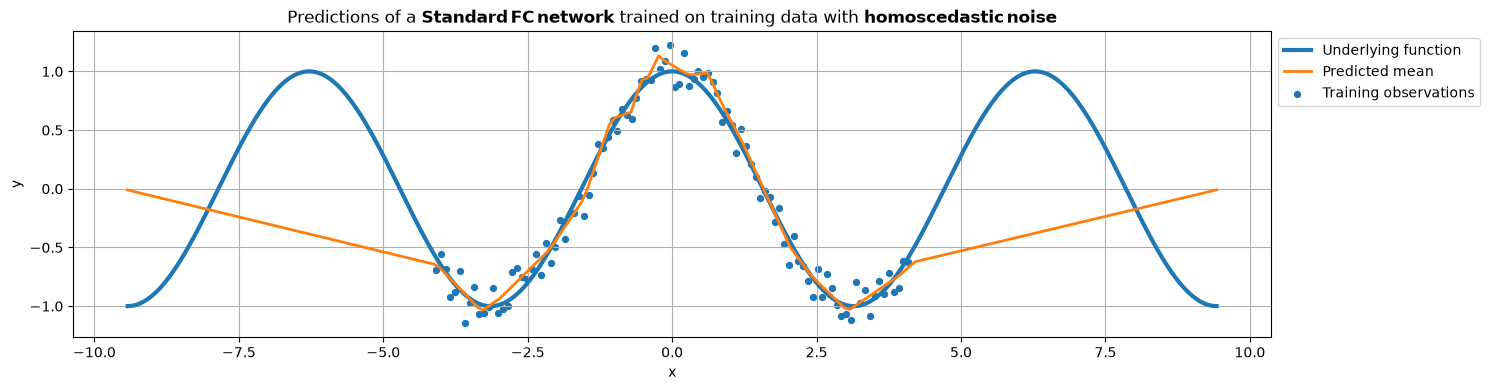

In [115]:
Y_test_pred_hom = standard_fc_network_forward(X_test.T, params_hom)
visualize_predictions(Y_test_pred_hom,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on training data with $\bf{homoscedastic\, noise}$',
                     X_train, Y_train_hom)

Compare the fit with the clean-data result. Does the network follow some of the noise? This can happen, but its extent depends on the data realization, optimization, and model capacity.

Next, use the labels with heteroscedastic noise.

Inside $[-1.3 \pi; 1.3 \pi ]$, the model fits some of the noise in the data, so it doesn't follow the curve as closely as with the clean data. Outside that range in which it extrapolates, both just extrapolate a linear relationship, though the slope is different between the two. 

In [116]:
# Initialize the network parameters
params_het = standard_fc_network_init(input_dim,
                                      layers_width,
                                      output_dim,
                                      key)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_het)

params_het,\
train_loss_het,\
train_mse_het,\
test_mse_het = run_training_loop(num_epochs,
                                 opt_state,
                                 X_train,
                                 Y_train_het,
                                 X_test,
                                 Y_test_true,
                                 len(layers_width)+1,
                                 loss_mse)

Starting loss: 0.562691 | Train MSE: 0.562691
Epoch 1 | T: 0.1935s | Train loss: 0.555696 | Train MSE: 0.555696 | Clean-test MSE (all): 0.502733
Epoch 200 | T: 0.0003s | Train loss: 0.020414 | Train MSE: 0.020414 | Clean-test MSE (all): 0.586137
Epoch 400 | T: 0.0004s | Train loss: 0.019360 | Train MSE: 0.019360 | Clean-test MSE (all): 0.518843
Epoch 600 | T: 0.0003s | Train loss: 0.019265 | Train MSE: 0.019265 | Clean-test MSE (all): 0.512209
Epoch 800 | T: 0.0003s | Train loss: 0.019634 | Train MSE: 0.019634 | Clean-test MSE (all): 0.507014
Epoch 1000 | T: 0.0004s | Train loss: 0.019181 | Train MSE: 0.019181 | Clean-test MSE (all): 0.506952
Final clean-test MSE (interpolation): 0.005873
Final clean-test MSE (extrapolation): 0.884959


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Standard\\, FC\\, network}$ trained on training data with $\\bf{heteroscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

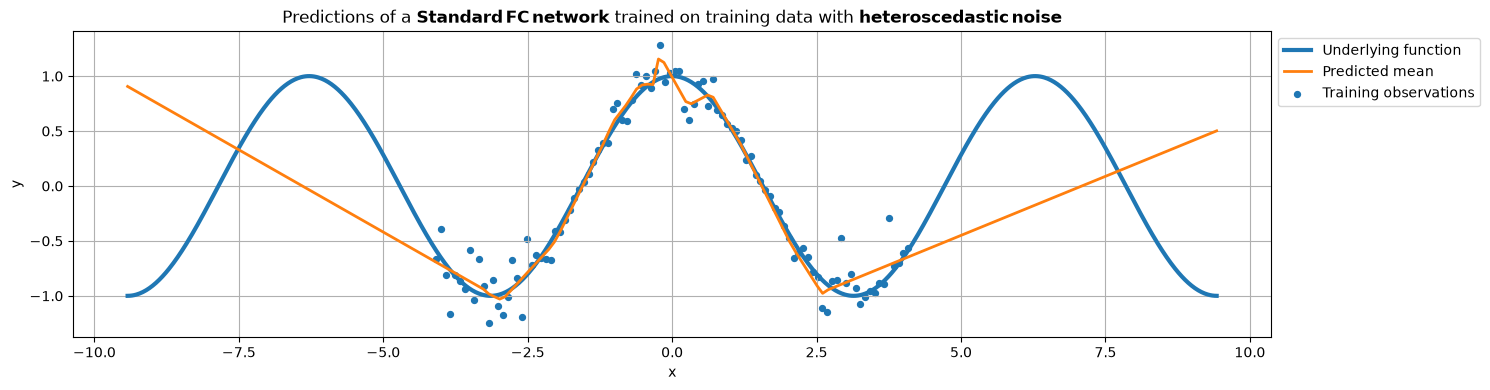

In [117]:
Y_test_pred_het = standard_fc_network_forward(X_test.T,
                                              params_het)
visualize_predictions(Y_test_pred_het,
                     r'Predictions of a $\bf{Standard\, FC\, network}$'
                     r' trained on training data with $\bf{heteroscedastic\, noise}$',
                     X_train, Y_train_het)

Compare both noisy-data fits. Do not assume that heteroscedastic noise must cause more overfitting: these two datasets also have different average noise variances. Describe what your run actually shows.

As expected, when the magnitude of the output is larger, the deviation from the true cosine curve is larger. Near $[1.5,2]$ and $[-2,-1.5]$, it models the cosine curve almost perfectly, but near $-2.7$, $0$ and $2.7$ in which the magnitude is §\approx 1$, the fit deviate significantly from the cosine function. Compared to the homoscedastic noise setting, the network trained with heteroscedastic noise follows the curve more closely where the magnitude of the target is smaller, but deviates more where the magnitude of the target is larger.

# Training with an Assumed Label-Noise Distribution

In the lectures, we discussed that one way to model aleatoric uncertainty is using maximum likelihood estimation (MLE) in tandem with a model that can output probability distributions. Here, we are going to follow this idea to see how well this approach can predict the aleatoric uncertainty.

## Modelling Aleatoric Uncertainty: Learning to predict a fixed (homoscedastic) uncertainty
For a maximum likelihood estimation we need to devise a likelihood function. Let's assume a Gaussian likelihood function, parametrized by a deep network to give its mean and variance, given an input. In this first part, we assume the deep network produces a fixed variance independent of the input sample while the mean is dependent on the input sample. That is, our likelihood function has the following form:

$$
P(y\mid\mathbf{x};\mathbf{\theta},\sigma)=\mathcal{N}(y;f_{\mathbf{\theta}}(\mathbf{x}),\sigma^2).
$$

Think(!) how this is the same as assuming an additive Gaussian noise with a fixed variance on the labels.

First, we introduce a scalar controlling the shared standard deviation and initialize the mean network as before.

The scalar $s$ stores a trainable log standard deviation, not a variance. For numerical protection on the noise-free dataset, the implementation uses $s_{\mathrm{eff}}=\max(s,\log\sigma_{\min})$ and $\sigma=\exp(s_{\mathrm{eff}})$ with $\sigma_{\min}=10^{-3}$. This is an explicit lower bound on the likelihood standard deviation, not an estimate of epistemic uncertainty. Use the same transformation for training and plotting.


In [118]:
# A small, explicit lower bound prevents a zero-variance Gaussian likelihood.
min_likelihood_std = 1e-3

def homoscedastic_log_std(params):
    return jnp.maximum(params[-1], jnp.log(min_likelihood_std))

# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_clean_data = standard_fc_network_init(input_dim,
                                                        layers_width,
                                                        output_dim,
                                                        key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_clean_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_clean_data)

Choose the network parameters and shared scale to maximize the likelihood:

$$
(\theta^*,s^*)=\operatorname*{arg\,max}_{\theta,s}
\prod_{i=1}^n\mathcal N\!\left(y_i;f_\theta(x_i),\exp(2s_{\mathrm{eff}})\right).
$$

Take the negative logarithm and write the equivalent minimization objective. Derive the sum form first, then divide the **entire objective** by $n$ for the implementation. Retain the Gaussian normalizing constant so numerical loss values are comparable.

### TODO — Derivation 1: homoscedastic Gaussian likelihood
Show the steps from the product of Gaussian densities to the mean negative log likelihood in terms of $s_{\mathrm{eff}}$ and the squared residuals. State whether the scale parameter is a standard deviation or a variance.

**Your derivation:**

Write $r_i=y_i-f_\theta(\mathbf{x}_i)$ for the residuals. The scale parameter $s_{\mathrm{eff}}$ is a **log standard deviation**, so $\sigma=e^{s_{\mathrm{eff}}}$ is the standard deviation and $\sigma^2=e^{2s_{\mathrm{eff}}}$ is the variance. One Gaussian density is

$$
\mathcal N\!\left(y_i;f_\theta(\mathbf{x}_i),e^{2s_{\mathrm{eff}}}\right)
=\frac{1}{\sqrt{2\pi\,e^{2s_{\mathrm{eff}}}}}e^{-\frac{r_i^2}{2e^{2s_{\mathrm{eff}}}}}
=\frac{e^{-s_{\mathrm{eff}}}}{\sqrt{2\pi}}e^{-\frac{r_i^2}{2}e^{-2s_{\mathrm{eff}}}}.
$$


$$
\begin{aligned}
-\log\prod_{i=1}^n\mathcal N\!\left(y_i;f_\theta(\mathbf{x}_i),e^{2s_{\mathrm{eff}}}\right)
&=-\sum_{i=1}^n\log\mathcal N\!\left(y_i;f_\theta(\mathbf{x}_i),e^{2s_{\mathrm{eff}}}\right)\\
&=\sum_{i=1}^n\left[\frac12\log(2\pi)+s_{\mathrm{eff}}+\frac{r_i^2}{2}\,e^{-2s_{\mathrm{eff}}}\right]\\
&=\frac n2\log(2\pi)+n\,s_{\mathrm{eff}}+\frac{e^{-2s_{\mathrm{eff}}}}{2}\sum_{i=1}^n r_i^2 .
\end{aligned}
$$

The scale is shared by all examples, so $s_{\mathrm{eff}}$ does not depend on $i$ and can be pulled out of the sum. Dividing the **entire** objective by $n$ does not change the minimizer and gives the mean negative log likelihood used in the implementation:

$$
\mathcal L(\theta,s)=\frac12\log(2\pi)+s_{\mathrm{eff}}+\frac{e^{-2s_{\mathrm{eff}}}}{2}\cdot\frac1n\sum_{i=1}^n\big(y_i-f_\theta(\mathbf{x}_i)\big)^2 .
$$

Implement the mean negative log likelihood below. Use `homoscedastic_log_std(params)` for the effective log standard deviation, including the documented lower bound. Keep prediction and target shapes identical. A negative Gaussian negative log likelihood is possible: densities, unlike probabilities of events, can exceed one.

In [119]:
def loss_mle_homoscedastic(params, X, Y):
    """TODO: implement the mean Gaussian negative log likelihood.

    params[:-1] contains the mean network. Obtain the effective log standard
    deviation with homoscedastic_log_std(params). Include the normalizing
    constant, average over examples, and return one differentiable scalar.
    """
    preds = standard_fc_network_forward(X, params[:-1])
    if preds.shape != Y.shape:
        raise ValueError("Predictions and targets must have identical shapes.")
    s_eff = homoscedastic_log_std(params)
    return 0.5 * jnp.log(2 * jnp.pi) + s_eff + jnp.exp(-2 * s_eff)/2 * jnp.mean((Y - preds) ** 2)

Starting loss: 6.243139 | Train MSE: 0.554691
Epoch 1 | T: 0.2982s | Train loss: 6.022954 | Train MSE: 0.547110 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0006s | Train loss: -0.773381 | Train MSE: 0.000458 | Clean-test MSE (all): 0.704757
Epoch 400 | T: 0.0003s | Train loss: -1.547039 | Train MSE: 0.000838 | Clean-test MSE (all): 0.856019
Epoch 600 | T: 0.0003s | Train loss: -2.127078 | Train MSE: 0.000131 | Clean-test MSE (all): 1.113776
Epoch 800 | T: 0.0004s | Train loss: -2.549250 | Train MSE: 0.000200 | Clean-test MSE (all): 1.161436
Epoch 1000 | T: 0.0003s | Train loss: -2.504273 | Train MSE: 0.000198 | Clean-test MSE (all): 1.093892
Final clean-test MSE (interpolation): 0.000189
Final clean-test MSE (extrapolation): 1.918965
The final trained homoscedastic standard deviation for clean data is:  0.02898447


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{clean\\, labels}$'}, xlabel='x', ylabel='y'>)

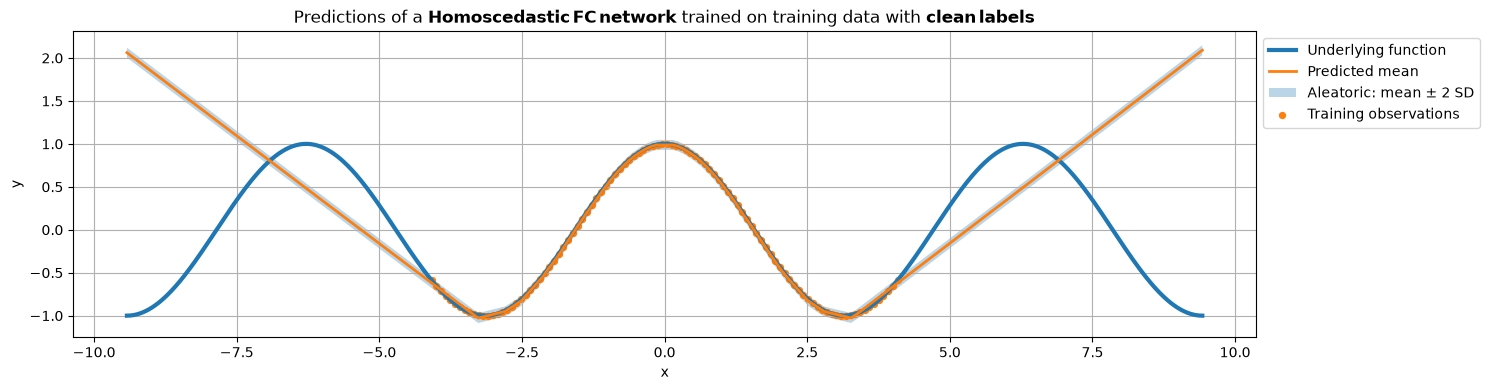

In [120]:
params_homo_model_clean_data,\
train_loss_homo_model_clean_data,\
train_mse_homo_model_clean_data,\
test_mse_homo_model_clean_data = run_training_loop(num_epochs,
                                                   opt_state, X_train,
                                                   Y_train_true, X_test,
                                                   Y_test_true,
                                                   len(layers_width)+1,
                                                   loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_clean_data))
print('The final trained homoscedastic standard deviation'
      ' for clean data is: ',
      sigma_param)

Y_test_pred_homo_model_clean_data = standard_fc_network_forward(X_test.T,
                                                                params_homo_model_clean_data[:-1])

visualize_predictions(Y_test_pred_homo_model_clean_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{clean\, labels}$',
                     X_train,
                     Y_train_true,
                     sigma_param)

How small is the learned standard deviation on clean data? For a fixed mean function, the unconstrained optimum satisfies $\sigma^2=\mathrm{MSE}_{\mathrm{train}}$. If the network exactly interpolates all labels, the Gaussian likelihood is unbounded as $\sigma\to0$: there is no finite, positive-variance MLE. The explicit lower bound prevents this numerical degeneracy, but it does not make the fit calibrated. A poor mean fit can instead inflate the learned scale.

Now fit the data with homoscedastic additive noise.

Starting loss: 6.565927 | Train MSE: 0.580514
Epoch 1 | T: 0.2126s | Train loss: 6.340560 | Train MSE: 0.573032 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0003s | Train loss: -0.557962 | Train MSE: 0.010770 | Clean-test MSE (all): 0.598547
Epoch 400 | T: 0.0006s | Train loss: -0.867060 | Train MSE: 0.009564 | Clean-test MSE (all): 0.442114
Epoch 600 | T: 0.0003s | Train loss: -0.921965 | Train MSE: 0.009261 | Clean-test MSE (all): 0.477916
Epoch 800 | T: 0.0005s | Train loss: -0.971800 | Train MSE: 0.008381 | Clean-test MSE (all): 0.478686
Epoch 1000 | T: 0.0003s | Train loss: -0.966049 | Train MSE: 0.008480 | Clean-test MSE (all): 0.510747
Final clean-test MSE (interpolation): 0.003966
Final clean-test MSE (extrapolation): 0.893056
The final trained homoscedastic standard deviation for data with fixed additive Gaussian noise is:  0.09280547


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{homoscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

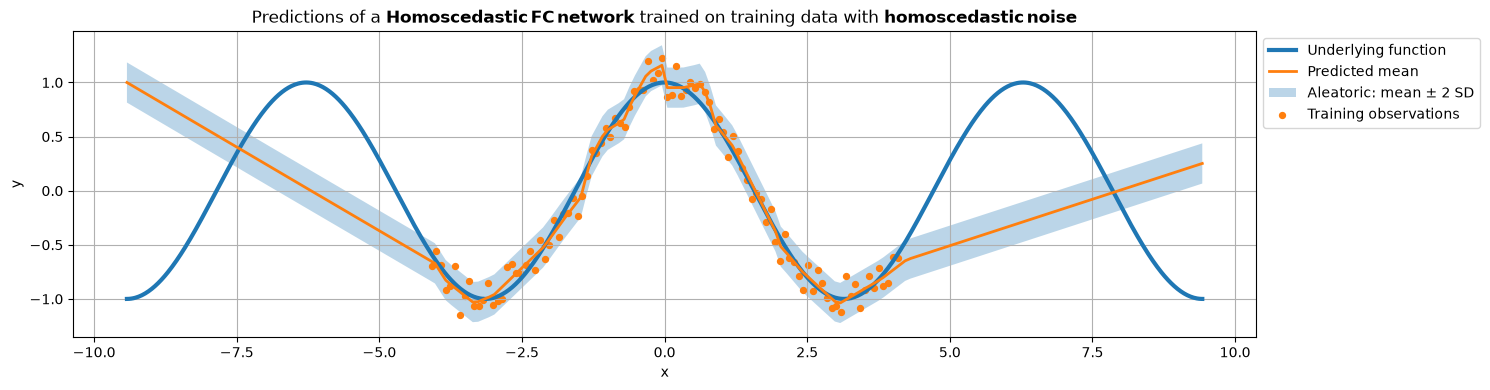

In [121]:
# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_homo_data = standard_fc_network_init(input_dim,
                                                       layers_width,
                                                       output_dim,
                                                       key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_homo_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_homo_data)

params_homo_model_homo_data,\
train_loss_homo_model_homo_data,\
train_mse_homo_model_homo_data,\
test_mse_homo_model_homo_data = run_training_loop(num_epochs,
                                                  opt_state,
                                                  X_train,
                                                  Y_train_hom,
                                                  X_test,
                                                  Y_test_true,
                                                  len(layers_width)+1,
                                                  loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_homo_data))
print('The final trained homoscedastic standard deviation '
      'for data with fixed additive Gaussian noise is: ',
      sigma_param)

Y_test_pred_homo_model_homo_data = standard_fc_network_forward(X_test.T,
                                                               params_homo_model_homo_data[:-1])

visualize_predictions(Y_test_pred_homo_model_homo_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{homoscedastic\, noise}$',
                     X_train,
                     Y_train_hom,
                     sigma_param)


Compare the learned standard deviation with the generating value $0.1$. Does the shaded band contain most training observations? Distinguish a useful visual check from a calibration test: these observations were used for fitting, and a flexible network can fit noise and underestimate the noise scale. Proper coverage assessment requires fresh noisy labels, preferably with interpolation and extrapolation reported separately. The clean test curve is not a set of draws from the noisy observation distribution.

Now fit the data with heteroscedastic label noise using the same fixed-variance model.

Yes, there are only very few points that are not contained within the two standard deviation band. This does not indicate good calibration, though. To test calibration, we need a held-out set to compare the predictions against.

Starting loss: 6.343144 | Train MSE: 0.562691
Epoch 1 | T: 0.2264s | Train loss: 6.127964 | Train MSE: 0.555680 | Clean-test MSE (all): 0.502732
Epoch 200 | T: 0.0004s | Train loss: -0.398572 | Train MSE: 0.021043 | Clean-test MSE (all): 0.527373
Epoch 400 | T: 0.0003s | Train loss: -0.534338 | Train MSE: 0.019895 | Clean-test MSE (all): 0.535295
Epoch 600 | T: 0.0003s | Train loss: -0.576848 | Train MSE: 0.018459 | Clean-test MSE (all): 0.635708
Epoch 800 | T: 0.0003s | Train loss: -0.588832 | Train MSE: 0.018031 | Clean-test MSE (all): 0.731544
Epoch 1000 | T: 0.0004s | Train loss: -0.597988 | Train MSE: 0.017703 | Clean-test MSE (all): 0.825303
Final clean-test MSE (interpolation): 0.004335
Final clean-test MSE (extrapolation): 1.444630
The final trained homoscedastic standard deviation for data with variable (heteroscedastic) noise is:  0.13436417


(<Figure size 1500x400 with 1 Axes>,
 <Axes: title={'center': 'Predictions of a $\\bf{Homoscedastic\\, FC\\, network}$ trained on training data with $\\bf{heteroscedastic\\, noise}$'}, xlabel='x', ylabel='y'>)

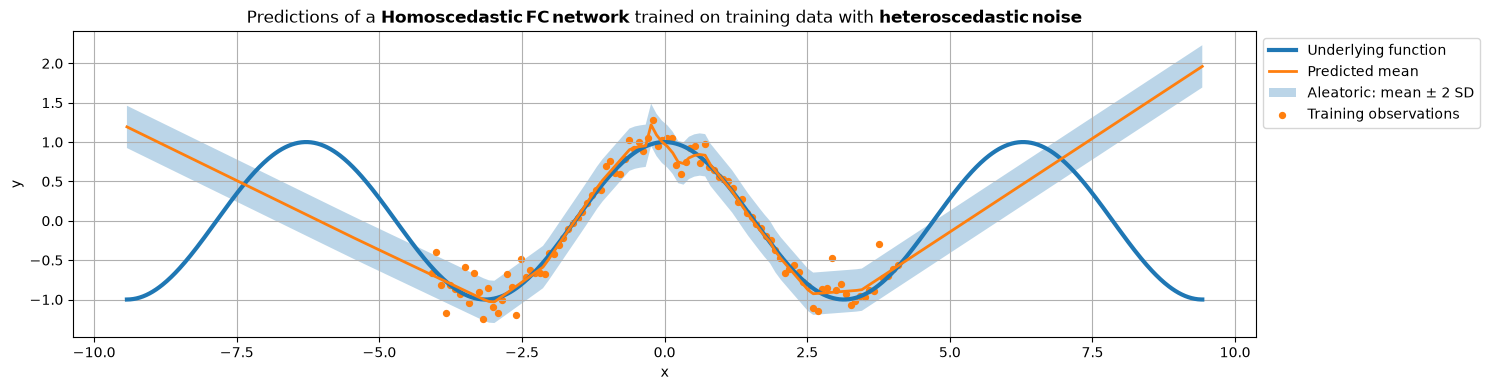

In [122]:
# One trainable scalar for the log standard deviation (not the variance).
sigma_param = jnp.array(jnp.log(0.2))

# Initialize the network parameters that will produce the mean of the likelihood's Gaussian
params_homo_model_het_data = standard_fc_network_init(input_dim,
                                                      layers_width,
                                                      output_dim,
                                                      key)

# Append the log-standard-deviation parameter, not the standard deviation.
params_homo_model_het_data.append(sigma_param)

# Defining an optimizer in Jax
opt_init, opt_update, get_params = optimizers.adam(step_size)
opt_state = opt_init(params_homo_model_het_data)

params_homo_model_het_data,\
train_loss_homo_model_het_data,\
train_mse_homo_model_het_data,\
test_mse_homo_model_het_data = run_training_loop(num_epochs,
                                                 opt_state,
                                                 X_train,
                                                 Y_train_het,
                                                 X_test,
                                                 Y_test_true,
                                                 len(layers_width)+1,
                                                 loss_mle_homoscedastic)

sigma_param = jnp.exp(homoscedastic_log_std(params_homo_model_het_data))
print('The final trained homoscedastic standard deviation '
      'for data with variable (heteroscedastic) noise is: ',
      sigma_param)

Y_test_pred_homo_model_het_data = standard_fc_network_forward(X_test.T, params_homo_model_het_data[:-1])

visualize_predictions(Y_test_pred_homo_model_het_data,
                     r'Predictions of a $\bf{Homoscedastic\, FC\, network}$'
                     r' trained on training data with $\bf{heteroscedastic\, noise}$',
                     X_train,
                     Y_train_het,
                     sigma_param)


Does one fixed standard deviation make sense everywhere when the true conditional standard deviation is $0.2|\cos(x)|$? Compare regions near the cosine's zeros with regions near its peaks. Explain how a shared scale can average over different local noise levels and mean-model errors. High overall training coverage does not establish correct local uncertainty.

Only the **homoscedastic likelihood** is implemented in this practical. Fitting a network that predicts an input-dependent likelihood variance is outside the present scope. Also, an aleatoric band is not expected to expand simply because an input is far from the training data: that requires a separate treatment of epistemic uncertainty.

No, the variance differs depending on the magnitude of the target, thus the fixed standard deviation band overestimates in regions in which the magnitude is small and underestimates in regions with high magnitude, such as near $x=0, x \approx -2.7, x \approx 2.7$. This effect occurs because the learned standard deviation has to fit both the low variance and high variance regions and thus averages both.

---


# Variational Inference for Deep Regression Networks
In this part of the practical we are interested in epistemic uncertainty estimation with deep networks based on the following paper.

[1] Blundell et al., ["Weight Uncertainty in Neural Networks"](https://proceedings.mlr.press/v37/blundell15.html), ICML 2015.

---



In order to model epistemic uncertainty, we can use Bayesian modelling to obtain a posterior distribution on model parameters:

$$
P(\mathbf{\theta}|\mathcal{D})= \frac{P(\mathcal{D}|\mathbf{\theta})P(\mathbf{\theta})}{P(\mathcal{D})}
$$




Using this posterior distribution, we can transfer the uncertainty in model parameters to uncertainty in predictive distribution, where, for a new test sample $\mathbf{x}$:



$$
P(y|\mathbf{x},\mathcal{D})=\int P(y|\mathbf{x},\mathbf{\theta})P(\mathbf{\theta}|\mathcal{D})d\theta.
$$



However, obtaining $P(\mathbf{\theta}|\mathcal{D})$ can be problematic due to the intractability of calculating $P(\mathcal{D})$. Thus, there are several techniques developed to approximate the posterior distribution $P(\mathbf{\theta}|\mathcal{D})$. One of these techniques is called Variational Inference (VI). In VI, we seek to identify another, simpler, distribution $Q_\omega(\theta)$, parametrized by $\omega$, that approximates $P(\theta|\mathcal{D})$. In VI, we can maximize the evidence lower bound (ELBO), or minimize a negated version, as follows (details provided in the course lectures and the VAE practical):




$$
\omega^*=\text{argmin}_{\omega} -\mathbb{E}_{Q_\omega(\theta)}[\log P(\mathcal{D}|\theta)]+\text{D}_{\text{KL}}(Q_\omega(\theta)||P(\theta))
$$



Assume the labels are conditionally independent given the inputs and weights. The inputs themselves are a fixed grid; they need not be independently sampled for this conditional likelihood to factorize:

$$
\omega^*=\operatorname*{arg\,min}_\omega
-\mathbb E_{Q_\omega(\theta)}\!\left[\sum_{i=1}^n\log P(y_i\mid x_i,\theta)\right]
+ D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right).
$$

Approximate the expectation by Monte Carlo samples from the weight distribution.

$$
\omega^*=\operatorname*{arg\,min}_\omega
\left[
-\frac{1}{S}\sum_{s=1}^{S}\sum_{i=1}^{n}\log P(y_i\mid x_i,\theta_s)
+D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right)
\right].
\tag{2}
$$


where, $\{\theta_s\}_{s=1}^{S}\sim Q_\omega(\theta)$.

Let us consider the following distributions:



$$
P(\theta)=\mathcal N(\mathbf 0_p,a^2I_p),\qquad a=10^{-2},
$$

$$
Q_{\omega=(\mu,\rho)}(\theta)=\mathcal N\!\left(\mu,\operatorname{diag}(\sigma^2)\right),
\qquad \sigma=\operatorname{softplus}(\rho),
$$

$$
P(y\mid x,\theta)=\mathcal N\!\left(y;f_\theta(x),c^2\right),\qquad c^2=1.
$$

These are the weight prior, approximate weight posterior, and conditional observation likelihood, respectively. The likelihood is **not** the posterior predictive distribution; the latter averages the likelihood over weights.

Here $p$ is the total number of scalar weights and biases, and $I_p$ is the identity matrix. The network outputs **one mean**, not both a mean and a variance: the observation variance $c^2$ is fixed in this part. Both weight covariance matrices are diagonal.

Following Blundell et al., optimize the unconstrained weight-scale parameter $\rho$ and obtain a positive weight standard deviation with the numerically stable `nn.softplus` function:



$$
\sigma=\text{log}(1+\exp(\rho))
$$



Plug these distributions into Equation (2), using one sampled network per full-batch gradient step ($S=1$). Expand the Gaussian log likelihood and the closed-form diagonal-Gaussian KL divergence. Include **all weights and biases** in the KL.

First derive the ordinary negative ELBO. Then introduce a coefficient $\beta=\texttt{kl\_weight}$ on the KL term to match the code. Explain the distinction between $\beta=1$ and the supplied $\beta=10^{-4}$.



$$
\widehat{\mathcal L}_\beta(\omega)
=-\sum_{i=1}^n\log P(y_i\mid x_i,\theta_\epsilon)
+\beta D_{\mathrm{KL}}\!\left(Q_\omega(\theta)\Vert P(\theta)\right),
\qquad \theta_\epsilon\sim Q_\omega.
$$

**Expand both terms in this expression.**

### TODO — Derivation 2: VI and the KL-weighted objective
Derive the Gaussian likelihood term and the diagonal-Gaussian KL term, substitute the reparameterized sample, and specify the reduction over training examples and over weight/bias coordinates. State which quantities are standard deviations and which are variances.

**Your derivation and interpretation of $\beta$:**

**Quantities.** The prior is $P(\theta)=\mathcal N(\mathbf 0_p,a^2I_p)$ with prior **standard deviation** $a=10^{-2}$ (variance $a^2$). The approximate posterior is $Q_\omega=\mathcal N(\mu,\operatorname{diag}(\sigma^2))$ with weight **standard deviations** $\sigma_j=\operatorname{softplus}(\rho_j)=\log(1+e^{\rho_j})$ (variances $\sigma_j^2$). The likelihood is $\mathcal N(y;f_\theta(x),c^2)$ with fixed observation **variance** $c^2=1$ (standard deviation $c$). All $p$ weights and biases are collected in $\theta$, $\mu$ and $\rho$.

**Likelihood term.** One observation gives
$$
-\log P(y_i\mid x_i,\theta)=\frac12\log(2\pi c^2)+\frac{\big(y_i-f_\theta(x_i)\big)^2}{2c^2}.
$$
With $S=1$ the expectation in Equation (2) is replaced by one reparameterized sample $\theta_\epsilon=\mu+\sigma\odot\epsilon$ with $\epsilon\sim\mathcal N(\mathbf 0_p,I_p)$, and the likelihood is **summed** over the $n$ training examples, which share this one sampled network:
$$
-\sum_{i=1}^n\log P(y_i\mid x_i,\theta_\epsilon)=\frac n2\log(2\pi c^2)+\frac{1}{2c^2}\sum_{i=1}^n\big(y_i-f_{\theta_\epsilon}(x_i)\big)^2 .
$$

**KL term.** Both distributions factorize over the $p$ coordinates, so the KL divergence is a sum of one-dimensional terms. For one coordinate with $q_j=\mathcal N(\mu_j,\sigma_j^2)$ and $p_j=\mathcal N(0,a^2)$:
$$
\begin{aligned}
D_{\mathrm{KL}}(q_j\Vert p_j)&=\mathbb E_{q_j}\!\left[\log q_j(\theta_j)-\log p_j(\theta_j)\right]\\
&=\mathbb E_{q_j}\!\left[-\frac12\log(2\pi\sigma_j^2)-\frac{(\theta_j-\mu_j)^2}{2\sigma_j^2}+\frac12\log(2\pi a^2)+\frac{\theta_j^2}{2a^2}\right]\\
&=\log\frac{a}{\sigma_j}-\frac12+\frac{\sigma_j^2+\mu_j^2}{2a^2},
\end{aligned}
$$
using $\mathbb E_{q_j}[(\theta_j-\mu_j)^2]=\sigma_j^2$ and $\mathbb E_{q_j}[\theta_j^2]=\sigma_j^2+\mu_j^2$. Summing over **all** weights and biases of every layer:
$$
D_{\mathrm{KL}}\!\left(Q_\omega\Vert P\right)=\sum_{j=1}^{p}\left[\log\frac{a}{\sigma_j}+\frac{\sigma_j^2+\mu_j^2}{2a^2}-\frac12\right],\qquad \sigma_j=\operatorname{softplus}(\rho_j).
$$

**Objective.** Inserting both terms gives the loss that is minimized in each full-batch step:
$$
\widehat{\mathcal L}_\beta(\omega)=\frac n2\log(2\pi c^2)+\frac{1}{2c^2}\sum_{i=1}^n\big(y_i-f_{\mu+\sigma\odot\epsilon}(x_i)\big)^2+\beta\sum_{j=1}^{p}\left[\log\frac{a}{\sigma_j}+\frac{\sigma_j^2+\mu_j^2}{2a^2}-\frac12\right].
$$
The constant $\frac n2\log(2\pi c^2)$ does not depend on $\omega$, but it is kept so that the loss values are comparable. The sampled network is differentiable in $\mu$ and $\rho$ through $\theta_\epsilon$, so gradients reach both. The one-sample likelihood term is a noisy but unbiased estimate of the expectation, and the KL term is exact. If the likelihood is averaged instead, the whole objective is divided by $n$, giving the mean NLL plus $\frac{\beta}{n}D_{\mathrm{KL}}$.

**Interpretation of $\beta$.** For $\beta=1$, $\widehat{\mathcal L}_1$ is an estimate of the ordinary negative ELBO, so minimizing it makes $Q_\omega$ the member of the mean-field family that is closest in KL divergence to the posterior $P(\theta\mid\mathcal D)\propto P(\mathcal D\mid\theta)P(\theta)$ for the stated likelihood and prior. For $\beta\ne1$ we have
$$
\mathbb E_{Q_\omega}\!\left[-\log P(\mathcal D\mid\theta)\right]+\beta D_{\mathrm{KL}}(Q_\omega\Vert P)
=\beta\left[\mathbb E_{Q_\omega}\!\left[-\tfrac1\beta\log P(\mathcal D\mid\theta)\right]+D_{\mathrm{KL}}(Q_\omega\Vert P)\right],
$$
so the minimizer approximates the *tempered* posterior $\propto P(\mathcal D\mid\theta)^{1/\beta}P(\theta)$. This is a different inference target, not just a different optimizer setting. With $\beta=10^{-4}$ the likelihood enters with the exponent $10^{4}$, as if every observation had been seen $10^4$ times, so the KL term becomes a weak regularizer.

The supplied value is a practical choice. The prior is very tight ($a=10^{-2}$, so $\frac{1}{2a^2}=5000$ multiplies every $\mu_j^2$), while the data term is a sum of only $n$ residuals scaled by $\frac{1}{2c^2}$. For $\beta=1$ the KL term would dominate and pull all weights towards zero, which makes it hard for the network to fit the data. A small $\beta$ lets the data term decide the mean function. The price is that the resulting weight distribution is much narrower than the ordinary posterior, so the epistemic variability it produces is not a calibrated Bayesian uncertainty, and the fixed $c^2=1$ additionally does not match the observation noise of the data.

==== End of my answer ====

To differentiate the Monte Carlo objective with respect to both the weight means and their scales, express a sampled weight as a differentiable transformation of parameter-independent Gaussian noise. This is the pathwise reparameterization trick; see Blundell et al. [1] and Kingma and Welling [2]. Draw independent noise for the weights and biases, and split the JAX key accordingly.



$$
\theta_s= \sigma\odot\epsilon + \mu \qquad \text{with }\; \epsilon \sim \mathcal{N}(\mathbf{0}_p, \mathbf{I}_p)
$$



Here $\odot$ denotes elementwise multiplication. Use `nn.softplus(rho)`, not a manually computed `log(1 + exp(rho))`, for numerical stability. One sampled network is shared across all input points in a forward pass; resample its weights at each training step.

**Objective and scale.** The ordinary negative ELBO is recovered only with $\beta=1$. The supplied $\beta=10^{-4}$ is retained as a teaching configuration, but optimizes a **KL-weighted variational objective**, not the ordinary posterior for the stated likelihood and prior. Do not interpret changing $\beta$ as merely changing the optimizer: it changes the inference target. Also, $c^2=1$ is intentionally fixed and differs substantially from the generated observation-noise variances. These choices do not provide a calibrated Bayesian model of the toy datasets.

Use a **sum over training examples** for the likelihood and a sum over every weight and bias for the KL. If using a mean likelihood instead, divide the whole objective by $n$, giving mean NLL plus $(\beta/n)\,\mathrm{KL}$. Averaging only the likelihood changes their balance.

**Uncertainty in the plots.** With this likelihood, the approximate predictive variance is

$$
\operatorname{Var}_{\widehat P}(y\mid x,\mathcal D)
=\underbrace{\operatorname{Var}_{Q_\omega}(f_\theta(x))}_{\text{parameter-induced epistemic component}}
+\underbrace{c^2}_{\text{assumed aleatoric component}}.
$$

The second component is assumed, not learned. For $\beta\ne1$, the weight distribution is the result of the KL-weighted objective rather than ordinary posterior VI. Report which band is shown; a mean $\pm2$ SD band need not contain 95% of a non-Gaussian predictive mixture.

[1] Blundell et al., [Weight Uncertainty in Neural Networks](https://proceedings.mlr.press/v37/blundell15.html), ICML 2015.  
[2] Kingma and Welling, [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114), ICLR 2014.  
For implementation details, see the JAX documentation on [random keys](https://docs.jax.dev/en/latest/random-numbers.html), [pure functions and JIT](https://docs.jax.dev/en/latest/notebooks/Common_Gotchas_in_JAX.html), and [optimizer step indices](https://docs.jax.dev/en/latest/jax.example_libraries.optimizers.html).

In [123]:
# VI network's configurations
input_dim = X_train.shape[1]
output_dim = Y_train_true.shape[1]
layers_width = [100, 40, 100]
kl_prior_mean = 0
kl_prior_sigma = 1e-2
kl_weight = 1e-4
likelihood_variance = 1.0  # c^2: fixed observation variance, not a learned noise level.
vi_num_epochs = 250
vi_step_size = 1e-2
vi_mc_samples = 100  # Prediction-time samples; training still uses S=1.

# Separate streams for initialization, stochastic training, diagnostics, and plots.
# The same streams are intentionally used across the three datasets for comparison.
vi_init_key, vi_train_key, vi_eval_key, vi_plot_key = random.split(
    random.PRNGKey(rand_seed + 1), 4)


In [124]:
# Initialize the parameters of a VI-based fully-connected layer
def vi_fc_layer_init(input_dim, output_dim, key, scale=1e-2):
    keys = random.split(key, 2)
    weights_mean = random.normal(keys[0], (output_dim, input_dim)) * scale
    weights_rho = -2*jnp.ones((output_dim, input_dim))
    biases_mean  = random.normal(keys[1], (output_dim, 1)) * scale
    biases_rho = -2*jnp.ones((output_dim, 1))
    return weights_mean, weights_rho, biases_mean, biases_rho

In [125]:
def vi_fc_layer_forward(input, weights_mean, weights_rho, biases_mean, biases_rho, key):
    """TODO: sample a layer with the Gaussian reparameterization trick.

    Convert rho to a standard deviation using nn.softplus. Split key for
    independent weight and bias noise, sample standard normals of matching
    shapes, form the weight/bias samples, then return weights @ input + biases.
    Use the same sampled layer for every column in input. Do not use NumPy
    randomness inside this differentiable JAX function.
    """
    weights_key, biases_key = random.split(key)
    weights_eps = random.normal(weights_key, weights_mean.shape)
    biases_eps = random.normal(biases_key, biases_mean.shape)
    weights = weights_mean + nn.softplus(weights_rho) * weights_eps
    biases = biases_mean + nn.softplus(biases_rho) * biases_eps
    return jnp.dot(weights, input) + biases

In [126]:
# Initialize a VI-based fully-connected network
def vi_fc_network_init(input_dim, layers_width, output_dim, key):
  network_feature_dims = [input_dim, *layers_width, output_dim]
  keys = random.split(key, len(network_feature_dims[:-1]))
  params = [vi_fc_layer_init(network_feature_dims[i],
                             network_feature_dims[i+1],
                             keys[i])
            for i in range(len(network_feature_dims[:-1]))]
  return params

In [127]:
# Forward pass of a VI-based fully-connected network
def vi_fc_network_forward(input, params, key, is_classification=False):

    representation = input
    keys = random.split(key, len(params))

    for (weights_mean, weights_rho, biases_mean, biases_rho), key in zip(params[:-1], keys[:-1]):
        representation = nn.relu(vi_fc_layer_forward(representation, weights_mean, weights_rho, biases_mean, biases_rho, key))
    representation = vi_fc_layer_forward(representation, params[-1][0], params[-1][1], params[-1][2], params[-1][3], keys[-1])

    if is_classification:
        return nn.log_softmax(representation, axis=0)
    return representation

In [128]:
vi_initial_params = vi_fc_network_init(input_dim, layers_width, output_dim, vi_init_key)

In [129]:
def kl_divergence_two_diagonal_gaussians(q_mu, q_sigma, p_mu, p_sigma):
    """KL[N(q_mu, diag(q_sigma**2)) || N(p_mu, diag(p_sigma**2))].

    All sigma arguments are strictly positive standard deviations. Each input
    may be a scalar or an array; non-scalar inputs must have the same number
    of coordinates. Scalars are broadcast to all coordinates. Sum over all
    coordinates without constructing a dense covariance matrix or mutating inputs.
    """
    q_mu, q_sigma, p_mu, p_sigma = [
        jnp.asarray(v).reshape(-1) for v in (q_mu, q_sigma, p_mu, p_sigma)
    ]
    q_mu, q_sigma, p_mu, p_sigma = jnp.broadcast_arrays(q_mu, q_sigma, p_mu, p_sigma)
    terms = (jnp.log(p_sigma) - jnp.log(q_sigma)
             + 0.5 * ((q_sigma / p_sigma) ** 2
                      + ((q_mu - p_mu) / p_sigma) ** 2 - 1.0))
    return jnp.sum(terms)

In [130]:
def vi_loss(params, X, Y, prior_mu, prior_sigma, kl_weight, key,
            likelihood_variance=1.0):
    """TODO: one-sample, full-batch Gaussian NLL + kl_weight * KL.

    Use the sampled network output (not its mean-weight substitute). Sum the
    Gaussian NLL over observations, including its normalizing constant.
    likelihood_variance is c^2, whereas prior_sigma is the prior standard
    deviation. Sum KL(q || p) over every layer's weights AND biases using
    nn.softplus(rho) as the approximate posterior standard deviation.
    kl_weight=1 gives the ordinary negative ELBO; other values change the target.
    """
    preds = vi_fc_network_forward(X, params, key)
    if preds.shape != Y.shape:
        raise ValueError("Predictions and targets must have identical shapes.")
    nll = 0.5 * jnp.sum(jnp.log(2 * jnp.pi * likelihood_variance)
                        + (Y - preds) ** 2 / likelihood_variance)
    kl = 0.0
    for weights_mean, weights_rho, biases_mean, biases_rho in params:
        kl += kl_divergence_two_diagonal_gaussians(
            weights_mean, nn.softplus(weights_rho), prior_mu, prior_sigma)
        kl += kl_divergence_two_diagonal_gaussians(
            biases_mean, nn.softplus(biases_rho), prior_mu, prior_sigma)
    return nll + kl_weight * kl

In [131]:
# Keep VI names separate from the deterministic/MLE training helpers.
@partial(jit, static_argnames=("opt_update_fn", "get_params_fn"))
def vi_update(step, params, X, Y, opt_state, key, prior_mu, prior_sigma,
              kl_weight, likelihood_variance, opt_update_fn, get_params_fn):
    value, grads = value_and_grad(vi_loss)(params, X, Y, prior_mu, prior_sigma,
                                          kl_weight, key, likelihood_variance)
    opt_state = opt_update_fn(step, grads, opt_state)
    return get_params_fn(opt_state), opt_state, value

vi_opt_init, vi_opt_update, vi_get_params = optimizers.adam(vi_step_size)
vi_opt_state = vi_opt_init(vi_initial_params)

In [132]:
def run_vi_training_loop(num_epochs, opt_state, X, Y, X_test, Y_test,
                         train_key, eval_key, prior_mu, prior_sigma, kl_weight,
                         likelihood_variance):
    """Start from a fresh state, with explicit keys and model hyperparameters.

    Logged training objectives and test diagnostics are evaluated AFTER the
    update. The fixed evaluation keys are common random numbers, intentionally
    reused across epochs for less noisy comparisons, never used for training.
    Clean-test expected conditional NLL is per observation, excludes the KL,
    and is NOT the negative log posterior-predictive mixture density.
    """
    params = vi_get_params(opt_state)
    train_objective, clean_test_expected_nll = [], []
    train_keys = random.split(train_key, num_epochs)
    eval_keys = random.split(eval_key, 16)

    @jit
    def diagnostics(params):
        # Average the stochastic training objective over fixed diagnostic draws.
        objectives = vmap(lambda k: vi_loss(params, X.T, Y.T, prior_mu,
                           prior_sigma, kl_weight, k, likelihood_variance))(eval_keys)
        test_preds = vmap(lambda k: vi_fc_network_forward(X_test.T, params, k))(eval_keys)
        nll = 0.5 * jnp.mean(jnp.log(2 * jnp.pi * likelihood_variance)
                            + (test_preds - Y_test.T) ** 2 / likelihood_variance)
        return jnp.mean(objectives), nll

    def record():
        objective, nll = map(float, diagnostics(params))
        if not np.all(np.isfinite([objective, nll])):
            raise FloatingPointError("Non-finite VI objective; check scales and gradients.")
        train_objective.append(objective)
        clean_test_expected_nll.append(nll)

    record()
    for epoch in range(num_epochs):
        start_time = time.perf_counter()
        params, opt_state, _ = vi_update(epoch, params, X.T, Y.T, opt_state,
                                         train_keys[epoch], prior_mu, prior_sigma,
                                         kl_weight, likelihood_variance,
                                         vi_opt_update, vi_get_params)
        record()
        if epoch == 0 or (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1} | T: {time.perf_counter() - start_time:.4f}s"
                  f" | Train objective (sum NLL + beta KL): {train_objective[-1]:.4f}"
                  f" | Clean-test expected NLL/point: {clean_test_expected_nll[-1]:.4f}")
    return params, train_objective, clean_test_expected_nll

In [133]:
def visualize_VI(params, X_train, Y_train, plot_title, key,
                 num_trials=100, likelihood_variance=1.0):
    """Show epistemic and total-predictive SD bands from sampled networks."""
    if num_trials < 2:
        raise ValueError("Use at least two Monte Carlo samples to estimate variance.")
    keys = random.split(key, num_trials)
    predict_samples = jit(vmap(lambda k: vi_fc_network_forward(X_test.T, params, k)))
    samples = np.asarray(predict_samples(keys))[:, 0, :]  # (samples, test inputs)
    mean = samples.mean(axis=0)
    epistemic_variance = samples.var(axis=0, ddof=1)
    epistemic_std = np.sqrt(epistemic_variance)
    total_std = np.sqrt(epistemic_variance + likelihood_variance)
    inside = (X_test[:, 0] >= X_train[:, 0].min()) & (X_test[:, 0] <= X_train[:, 0].max())
    for label, mask in (("interpolation", inside), ("extrapolation", ~inside)):
        if np.any(mask):
            mse = np.mean((mean[mask] - Y_test_true.ravel()[mask]) ** 2)
            print(f"{label}: posterior-mean clean MSE={mse:.6f}, "
                  f"mean epistemic SD={epistemic_std[mask].mean():.6f}, "
                  f"mean total SD={total_std[mask].mean():.6f}")
    visualize_predictions(mean, plot_title, X_train, Y_train, epistemic_std,
                          uncertainty_label="Epistemic: mean ± 2 SD",
                          total_sigma_param=total_std)
    return {"mean": mean, "epistemic_std": epistemic_std, "total_std": total_std}

Epoch 1 | T: 1.2716s | Train objective (sum NLL + beta KL): 187.5556 | Clean-test expected NLL/point: 1.2514
Epoch 50 | T: 0.0030s | Train objective (sum NLL + beta KL): 165.9590 | Clean-test expected NLL/point: 2.2497
Epoch 100 | T: 0.0028s | Train objective (sum NLL + beta KL): 164.9757 | Clean-test expected NLL/point: 4.4238
Epoch 150 | T: 0.0034s | Train objective (sum NLL + beta KL): 147.9053 | Clean-test expected NLL/point: 1.7285
Epoch 200 | T: 0.0036s | Train objective (sum NLL + beta KL): 137.2535 | Clean-test expected NLL/point: 3.9848
Epoch 250 | T: 0.0020s | Train objective (sum NLL + beta KL): 129.1560 | Clean-test expected NLL/point: 2.4586
interpolation: posterior-mean clean MSE=0.061871, mean epistemic SD=0.294346, mean total SD=1.046547
extrapolation: posterior-mean clean MSE=5.056017, mean epistemic SD=0.819683, mean total SD=1.306418


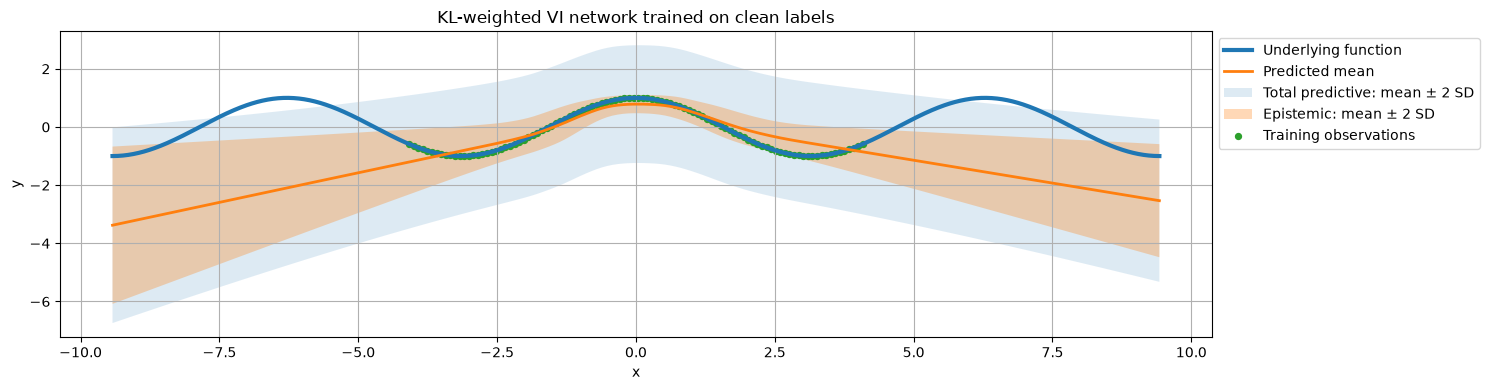

In [134]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_clean, train_objective_vi_clean, test_expected_nll_vi_clean = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_true, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_clean = visualize_VI(
    params_vi_clean, X_train, Y_train_true,
    "KL-weighted VI network trained on clean labels",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

Epoch 1 | T: 0.0026s | Train objective (sum NLL + beta KL): 188.8113 | Clean-test expected NLL/point: 1.2513
Epoch 50 | T: 0.0038s | Train objective (sum NLL + beta KL): 165.8737 | Clean-test expected NLL/point: 1.8388
Epoch 100 | T: 0.0026s | Train objective (sum NLL + beta KL): 157.1732 | Clean-test expected NLL/point: 1.5384
Epoch 150 | T: 0.0045s | Train objective (sum NLL + beta KL): 150.0715 | Clean-test expected NLL/point: 1.6443
Epoch 200 | T: 0.0024s | Train objective (sum NLL + beta KL): 139.7288 | Clean-test expected NLL/point: 3.0182
Epoch 250 | T: 0.0027s | Train objective (sum NLL + beta KL): 131.1834 | Clean-test expected NLL/point: 1.7666
interpolation: posterior-mean clean MSE=0.103215, mean epistemic SD=0.234905, mean total SD=1.028307
extrapolation: posterior-mean clean MSE=2.816710, mean epistemic SD=0.627932, mean total SD=1.189421


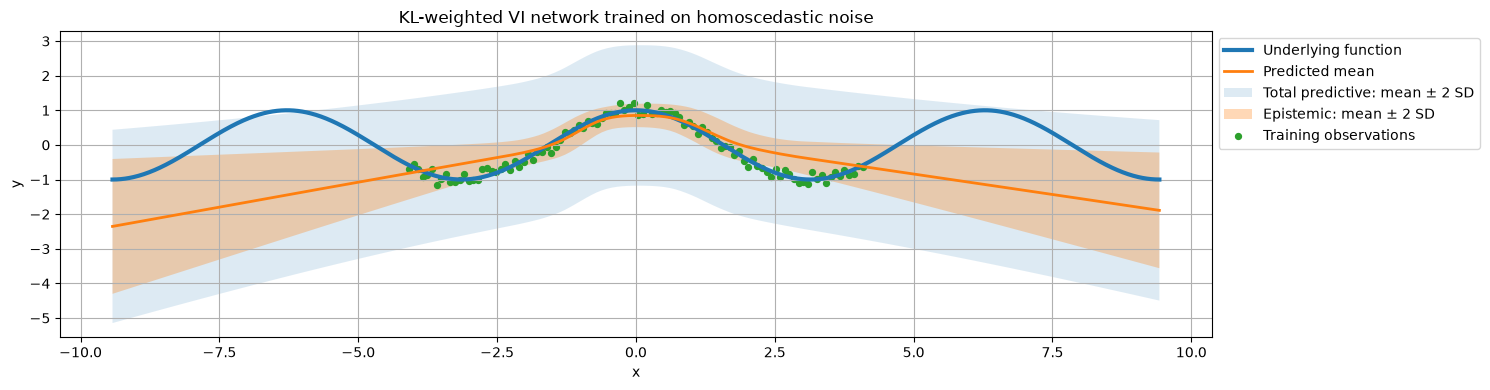

In [135]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_hom, train_objective_vi_hom, test_expected_nll_vi_hom = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_hom, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_hom = visualize_VI(
    params_vi_hom, X_train, Y_train_hom,
    "KL-weighted VI network trained on homoscedastic noise",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

Epoch 1 | T: 0.0028s | Train objective (sum NLL + beta KL): 188.0309 | Clean-test expected NLL/point: 1.2507
Epoch 50 | T: 0.0025s | Train objective (sum NLL + beta KL): 164.8019 | Clean-test expected NLL/point: 1.6746
Epoch 100 | T: 0.0026s | Train objective (sum NLL + beta KL): 160.4665 | Clean-test expected NLL/point: 3.1483
Epoch 150 | T: 0.0024s | Train objective (sum NLL + beta KL): 145.8889 | Clean-test expected NLL/point: 1.7945
Epoch 200 | T: 0.0024s | Train objective (sum NLL + beta KL): 134.9602 | Clean-test expected NLL/point: 2.9264
Epoch 250 | T: 0.0023s | Train objective (sum NLL + beta KL): 130.8823 | Clean-test expected NLL/point: 2.3900
interpolation: posterior-mean clean MSE=0.049863, mean epistemic SD=0.248206, mean total SD=1.032213
extrapolation: posterior-mean clean MSE=4.776987, mean epistemic SD=0.679539, mean total SD=1.218803


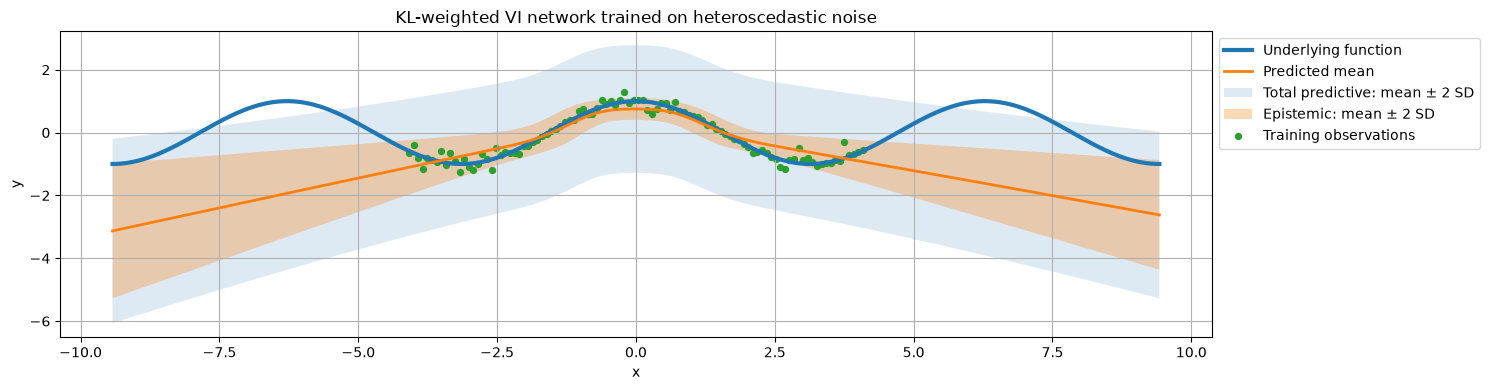

In [136]:
# vi_opt_state is the unchanged INITIAL state: this is a fresh fit, not fine-tuning.
params_vi_het, train_objective_vi_het, test_expected_nll_vi_het = run_vi_training_loop(
    vi_num_epochs, vi_opt_state, X_train, Y_train_het, X_test, Y_test_true,
    vi_train_key, vi_eval_key, kl_prior_mean, kl_prior_sigma, kl_weight,
    likelihood_variance)
prediction_vi_het = visualize_VI(
    params_vi_het, X_train, Y_train_het,
    "KL-weighted VI network trained on heteroscedastic noise",
    vi_plot_key, num_trials=vi_mc_samples, likelihood_variance=likelihood_variance)

### Interpreting the VI results
**Epistemic behavior.** Compare the estimated function variability inside and outside the training interval. More uncertainty away from observed data is a useful behavior to investigate, **not a correctness guarantee**. A valid implementation can be overconfident outside the training range because of its architecture, prior, variational family, or optimization. Neither Bayesian inference nor a mean-field approximation guarantees monotonic uncertainty growth with distance.

**Aleatoric versus total uncertainty.** The darker band reflects variation in $f_\theta(x)$ over sampled weights. The wider band additionally includes the fixed $c^2=1$. This assumed observation variance is not learned and does not match either noisy-data generator; in particular it cannot reproduce the heteroscedastic noise profile. The labels on these bands describe components of the fitted model, not certified calibration.

**Fit and approximation.** A weak mean fit can reflect the tight prior, single-sample training noise, limited training, and the chosen KL coefficient. Inspect the objective and predictions rather than treating poor fit as proof that the implementation is correct. Increasing prediction-time samples reduces Monte Carlo error, not inference bias. Use these results to discuss the limitations of this simplified KL-weighted, mean-field treatment.

For each dataset, explain what the two bands represent, whether the mean fits the observed region, and how the estimated epistemic variability changes outside that region. State the assumptions that prevent these plots alone from demonstrating calibrated uncertainty.

For a discussion of limitations of variational uncertainty estimates, see Foong et al., [On the Expressiveness of Approximate Inference in Bayesian Neural Networks](https://arxiv.org/abs/1909.00719), NeurIPS 2020. Their results distinguish shallow-network representational restrictions from inference problems that can persist in deeper networks.

1. The darker band is the epistemic band: it shows $\pm 2$ standard deviations of $f_\theta(x)$ over 100 networks sampled from $Q_\omega$, so it only reflects the uncertainty about the weights. The wider band additionally includes the fixed observation variance, so its standard deviation is $\sqrt{\operatorname{Var}_{Q_\omega}(f_\theta(x))+c^2}$ with $c^2=1$. Most of its width therefore comes from the assumed $c$ and not from anything the model learned. The actual noise is much smaller ($c=1$ vs. the learned standard deviations of $\approx 0.03$, $\approx 0.09$ and $\approx 0.13$ for the clean, homoscedastic and heteroscedastic data in the MLE part), so the wider band is far too wide in the observed region. For the clean data it is wrong by construction, as there is no noise at all.
2. In all three cases the posterior mean follows the cosine inside the training interval, but worse than the MLE network. The clean-test MSE in the interpolation region is $\approx 0.06$ (clean), $\approx 0.10$ (homoscedastic) and $\approx 0.05$ (heteroscedastic), compared to $\approx 0.0002$, $\approx 0.004$ and $\approx 0.004$ for the MLE network. A plausible reason is the very tight prior ($a=10^{-2}$) together with only one sampled network per update and 250 epochs. The order between the datasets should not be interpreted, as it is a single run.
3. Outside of the training interval the epistemic variability grows in all three cases. The mean epistemic standard deviation increases from $\approx 0.29$ to $\approx 0.82$ (clean), from $\approx 0.23$ to $\approx 0.63$ (homoscedastic) and from $\approx 0.25$ to $\approx 0.68$ (heteroscedastic), so by a factor of about $2.7$. The total standard deviation only grows from $\approx 1.03$-$1.05$ to $\approx 1.19$-$1.31$, because the constant $c^2=1$ dominates it. The growth is too small, though: the root of the clean-test MSE in the extrapolation region is $\approx 2.25$, $\approx 1.68$ and $\approx 2.19$, which is about $2.7$ to $3.2$ times the mean epistemic standard deviation. So the model is overconfident outside the training interval even though its uncertainty increases there.
4. The plots alone cannot show calibrated uncertainty for several reasons. The observation variance $c^2=1$ is fixed and does not match the noise of the data. With $\beta=10^{-4}$ we optimize a KL-weighted objective, i.e. an approximation of a tempered posterior and not of the ordinary posterior for the stated prior and likelihood. The variational family is a diagonal Gaussian over the weights and the prior is very tight. Furthermore, the predictive distribution is a mixture and not Gaussian, so a $\pm 2$ standard deviation band does not have to contain $95\%$ of the data. Finally, everything is based on a single run and, as in the earlier parts, we would need a held-out set to compare the predictions against in order to assess calibration.

Finally, approximately how long did it take you to complete this practical?

The full practical took us **10 hours**.

### LLM Usage Report
1. I use Claude Opus 5.5/Sonnet 5.5 to review my implementation, help me find bugs, sometimes fix the code if its minor issues or to suggest more efficient implementations that the one I came up with. Furthermore, I let it review my text answers regarding inconsistencies, flaws or inaccuracies and I improved my answers based on the points mentioned.
2. In my experience LLMs can be "abused" by just letting them do the entire work which leads to a quick completion of the assignment, but one defeats the entire purpose of learning anything. Therefore, I like to do the work myself and let the LLM review my work, discuss solutions and dive deeper into aspects that interest me, to boost my learning and understanding instead. For that purpose they are very well-suited and a great tool that I wouldn't want to miss anymore, but it can be hard at times to resist the urge of just letting it give you the answer straight away if one is stuck/struggling with some task.
3. I think you should allow them because realistically students are going to use them anyways and by now they are definitely here to stay, so I think it's best to find a good way of integrating them into the learning/teaching process that boosts understanding instead of banning them.